# LightGBM

Els models estadístics (SARIMA, TBATS) assumeixen una estructura lineal i paramètrica. Una alternativa és tractar el forecasting com un problema de regressió supervisada: donat un vector de features derivades de l'historial, el calendari i el context, predir el valor futur. Aquí apliquem LightGBM, un gradient boosting eficient amb datasets de mida moderada que tolera bé la multicolinealitat de les features temporals.

L'estratègia escollida és la direct multi-step: en lloc de predir h=1 i reutilitzar la predicció com a input per a h=2 (estratègia recursiva, que propaga errors), entrenem un model independent per a cada horitzó h=1..12. El cost computacional és superior, però s'elimina l'acumulació d'errors en horitzons llargs, especialment important per a un forecast de 12 mesos.

Les features del model es divideixen en sis grups: els lags temporals (retards 1, 2, 3, 6 i 12 mesos) aporten informació directa sobre l'autocorrelació; les rolling stats (mitjana i desviació a 3, 6 i 12 mesos) capturen la tendència local i la volatilitat recent; l'encoding cíclic del mes (sin/cos) codifica l'estacionalitat sense la discontinuïtat dels dummies de mes; el trend (índex temporal) permet capturar la tendència global creixent; les dummies de COVID i MOVES III recullen els efectes d'intervenció identificats a l'EDA; i la ràtio YoY captura el patró de creixement any rere any.

El principal factor limitant és l'escassetat de dades: amb N≈84 mostres de train per sèrie, els models de ML tendeixen a generalitzar pitjor que els estadístics. L'experiment és honest: volem quantificar fins a quin punt el boosting és competitiu en aquest context i comparar-ho directament amb els models estadístics.

> Prerequisit: executar `data_preparation.ipynb` primer.

In [1]:
import sys
sys.path.insert(0, '../../src')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

from features import (
    TECNOLOGIES_MODELITZABLES,
    build_ml_features, get_feature_columns
)
from evaluation import compute_metrics
from plotting import format_ts_ax

DATA_DIR    = Path('../../data/processed')
RESULTS_DIR = DATA_DIR / 'results'
FIGURES_DIR = Path('../../figures')

plt.rcParams.update({'figure.dpi': 120})
TECNOLOGIES = TECNOLOGIES_MODELITZABLES + ['Total']
H = 12
FEATURE_COLS = get_feature_columns()

In [2]:
train_set = pd.read_csv(DATA_DIR / 'train_set.csv', parse_dates=['date'])
test_set  = pd.read_csv(DATA_DIR / 'test_set.csv',  parse_dates=['date'])
pivot_test = pd.read_csv(DATA_DIR / 'pivot_test.csv', index_col='date', parse_dates=True)
print(f'Train: {train_set["date"].min().date()} → {train_set["date"].max().date()}')
print(f'Test:  {test_set["date"].min().date()}  → {test_set["date"].max().date()}')
print(f'Features: {FEATURE_COLS}')

Train: 2017-01-01 → 2024-12-01
Test:  2025-01-01  → 2025-12-01
Features: ['lag_1', 'lag_2', 'lag_3', 'lag_6', 'lag_12', 'rolling_mean_3', 'rolling_mean_6', 'rolling_mean_12', 'rolling_std_3', 'rolling_std_6', 'rolling_std_12', 'month_sin', 'month_cos', 'quarter', 'trend', 'covid_dummy', 'moves3_dummy', 'yoy_ratio']


## 1. Feature engineering


In [3]:
# build_ml_features per tecnologia: afegeix lags, rolling, date, dummies
tech_features = {}
for tech in TECNOLOGIES:
    df_tech = train_set[train_set['Tecnologia'] == tech][['date', 'Matriculacions']].copy()
    df_feat = build_ml_features(df_tech)
    df_feat = df_feat.dropna(subset=FEATURE_COLS)  # elimina els primers mesos sense lags
    tech_features[tech] = df_feat

example = tech_features['Total']
print(f'Exemple (Total): {example.shape} → {len(example)} mostres de train amb totes les features')
example[FEATURE_COLS].tail(3)

Exemple (Total): (84, 21) → 84 mostres de train amb totes les features


,lag_1,lag_2,lag_3,lag_6,lag_12,rolling_mean_3,rolling_mean_6,rolling_mean_12,rolling_std_3,rolling_std_6,rolling_std_12,month_sin,month_cos,quarter,trend,covid_dummy,moves3_dummy,yoy_ratio
93,5834.0,4082.0,6934.0,5360.0,5900.0,5616.666667,5727.333333,5620.416667,1438.367593,1016.863937,743.767615,-8.660254e-01,0.500000,4,93,0,1,0.988814
94,7311.0,5834.0,4082.0,5522.0,5803.0,5742.333333,6052.500000,5738.000000,1616.450535,1175.476712,889.284084,-5.000000e-01,0.866025,4,94,0,1,1.259866
95,6330.0,7311.0,5834.0,6632.0,5796.0,6491.666667,6187.166667,5781.916667,751.654398,1148.520164,905.648081,-2.449294e-16,1.000000,4,95,0,1,1.092133


## 2. Entrenament LightGBM (direct multi-step)


In [4]:
import lightgbm as lgb

trained_models  = {}  # tech -> {h: lgb_model}
forecast_records = []
metrics_records  = []

LGB_PARAMS = dict(
    n_estimators=500,
    learning_rate=0.05,
    num_leaves=31,
    subsample=0.8,
    colsample_bytree=0.8,
    verbose=-1,
)

print('Entrenament LightGBM per tecnologia...')
for tech in TECNOLOGIES:
    df_feat = tech_features[tech]
    X = df_feat[FEATURE_COLS].values
    y = df_feat['Matriculacions'].values

    # Fila de test: necessitem els lags calculats sobre el train complet
    df_tech_full = train_set[train_set['Tecnologia'] == tech][['date', 'Matriculacions']].copy()
    df_full_feat = build_ml_features(df_tech_full)
    X_test_row = df_full_feat[FEATURE_COLS].iloc[[-1]].values

    models_h = {}
    preds = []
    for h in range(1, H + 1):
        # Target: y desplaçat h posicions cap al futur
        n_valid = len(y) - h
        X_h = X[:n_valid]
        y_h = y[h:]

        model = lgb.LGBMRegressor(**LGB_PARAMS)
        model.fit(X_h, y_h)
        models_h[h] = model
        pred_h = max(model.predict(X_test_row)[0], 0)
        preds.append(pred_h)

    trained_models[tech] = models_h
    y_pred = np.array(preds)
    y_test = pivot_test[tech].values

    y_train_vals = train_set[train_set['Tecnologia'] == tech]['Matriculacions'].values
    m = compute_metrics(y_test, y_pred, y_train_vals)
    m.update({'Tecnologia': tech, 'Model': 'LightGBM'})
    metrics_records.append(m)

    for i, date in enumerate(pivot_test.index):
        forecast_records.append({'date': date, 'Tecnologia': tech,
                                 'Model': 'LightGBM',
                                 'predicted': y_pred[i], 'actual': y_test[i]})
    print(f'  {tech:35s}: RMSE={m["RMSE"]:.0f}, MAPE={m["MAPE"]:.1f}%')

df_metrics   = pd.DataFrame(metrics_records)
df_forecasts = pd.DataFrame(forecast_records)

Entrenament LightGBM per tecnologia...


  Elèctric                           : RMSE=607, MAPE=30.1%


  Gasolina Mild Hybrid               : RMSE=442, MAPE=17.6%


  Gasolina/Elèctric                  : RMSE=606, MAPE=19.9%


  Gasolina/Elèctric Endollable       : RMSE=731, MAPE=46.6%


  Diesel Mild Hybrid                 : RMSE=47, MAPE=12.9%


  Diesel/Elèctric Endollable         : RMSE=27, MAPE=48.0%


  Total                              : RMSE=2350, MAPE=24.1%


## 3. Feature Importance (Total, h=1)


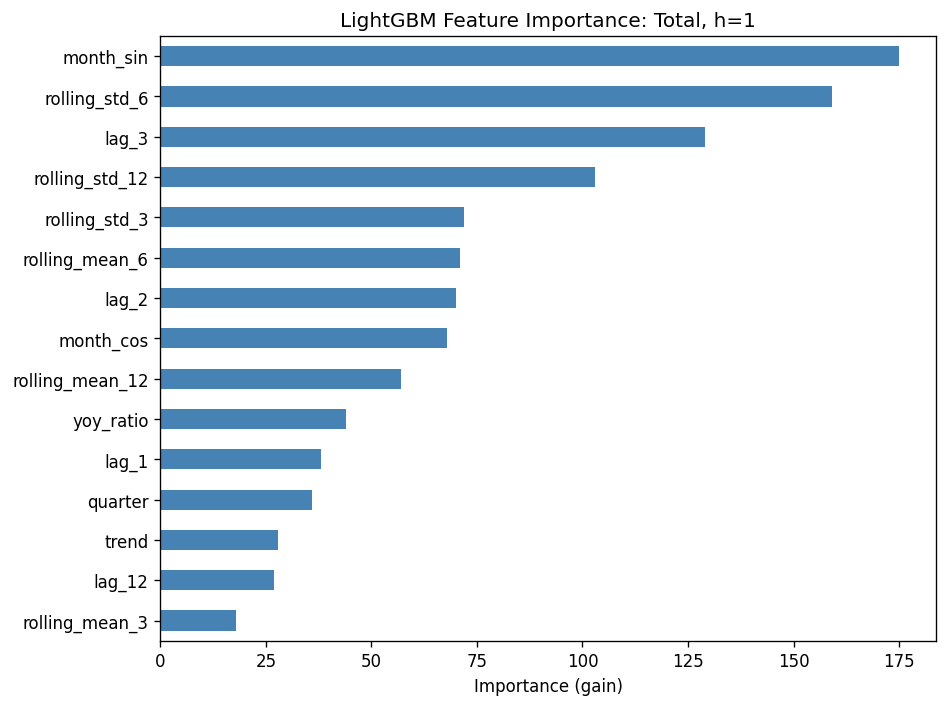

In [5]:
model_h1 = trained_models['Total'][1]
importance = pd.Series(model_h1.feature_importances_, index=FEATURE_COLS).sort_values(ascending=True)

fig, ax = plt.subplots(figsize=(8, 6))
importance.tail(15).plot.barh(ax=ax, color='steelblue')
ax.set_title('LightGBM Feature Importance: Total, h=1', fontsize=12)
ax.set_xlabel('Importance (gain)')
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_11_lgbm_feature_importance.png', bbox_inches='tight')
plt.show()

## 4. Visualització 


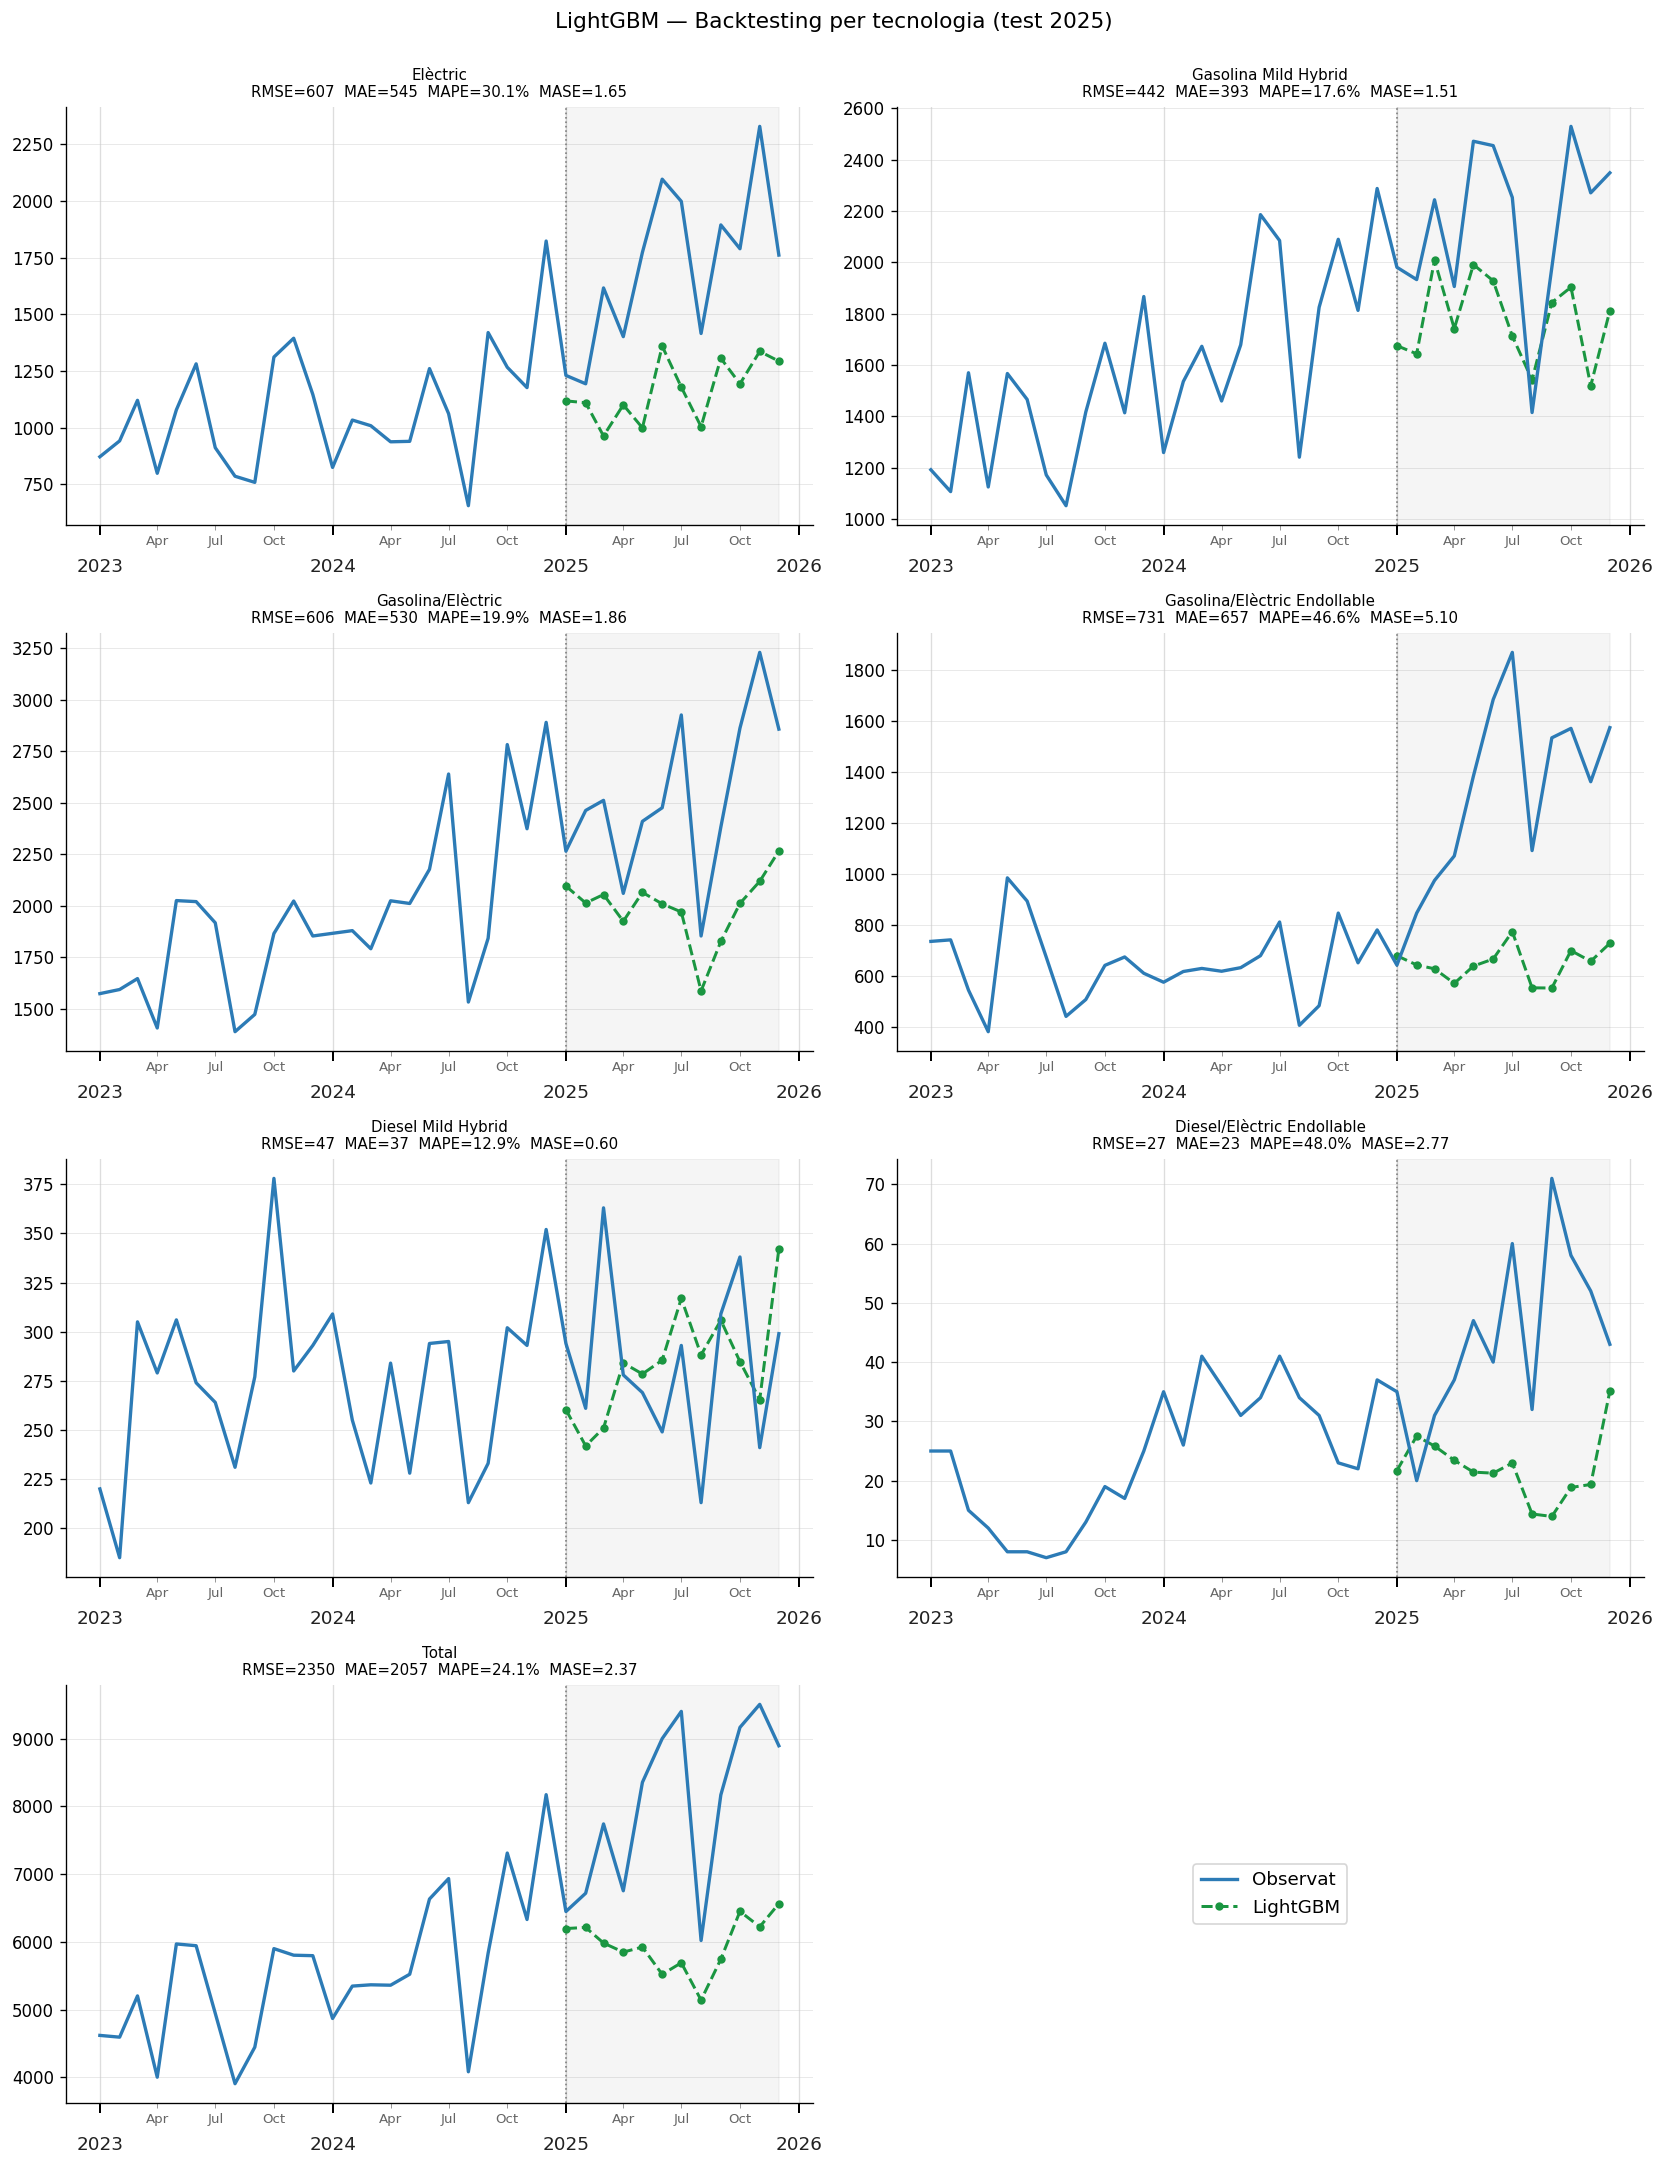

In [6]:
from plotting import plot_backtest_per_tech

pivot_train = pd.read_csv(DATA_DIR / 'pivot_train.csv', index_col='date', parse_dates=True)

plot_backtest_per_tech(
    pivot_train, pivot_test, df_forecasts, df_metrics,
    tecnologies=TECNOLOGIES, model_name='LightGBM',
    save_path=FIGURES_DIR / 'fig_lgbm_backtest_per_tech.png',
    color_pred='#1a9641',
)
plt.show()

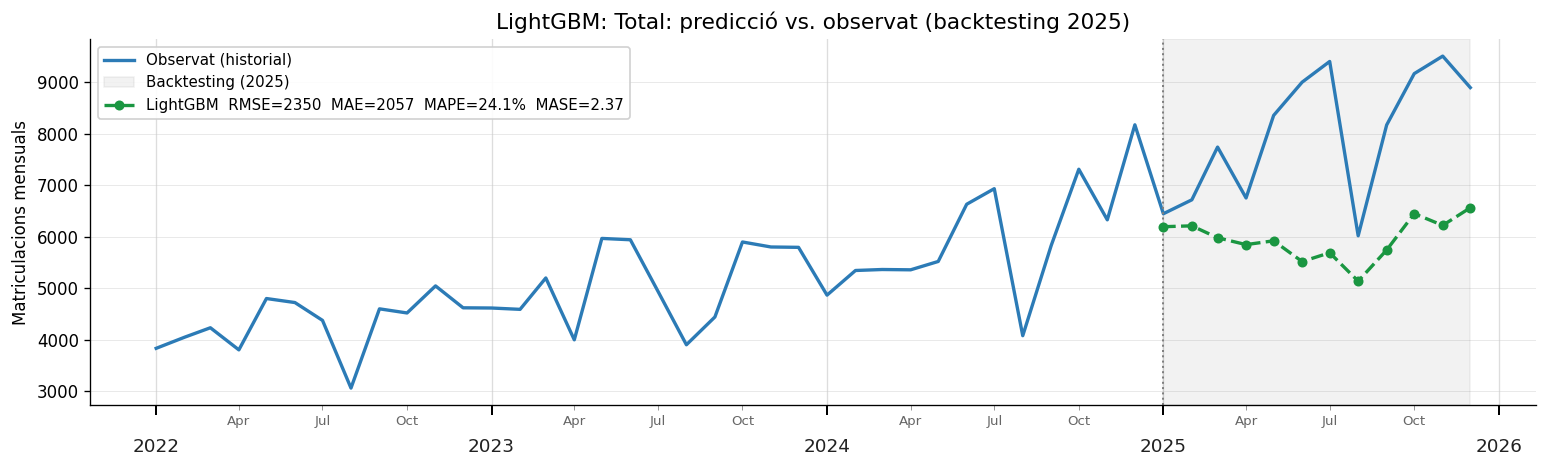

In [7]:
tech = 'Total'

fig, ax = plt.subplots(figsize=(13, 4))

y_train_plot = pivot_train[tech].iloc[-36:]
y_test_plot  = pivot_test[tech]
observed_dates = list(y_train_plot.index) + list(y_test_plot.index)
observed_vals  = list(y_train_plot.values) + list(y_test_plot.values)
ax.plot(observed_dates, observed_vals, color='#2c7bb6', lw=2, label='Observat (historial)')

ax.axvspan(pivot_test.index[0], pivot_test.index[-1], alpha=0.10, color='gray', label='Backtesting (2025)')
ax.axvline(pivot_test.index[0], color='gray', ls=':', lw=1.2)

sub = df_forecasts[(df_forecasts['Tecnologia'] == tech) &
                   (df_forecasts['Model'] == 'LightGBM')].sort_values('date')
m_total = df_metrics[df_metrics['Tecnologia'] == tech].iloc[0]
label = (f'LightGBM  RMSE={m_total["RMSE"]:.0f}  MAE={m_total["MAE"]:.0f}  '
         f'MAPE={m_total["MAPE"]:.1f}%  MASE={m_total["MASE"]:.2f}')
ax.plot(pd.to_datetime(sub['date']), sub['predicted'],
        color='#1a9641', lw=2, ls='--', marker='o', ms=5, label=label)

ax.set_title(f'LightGBM: {tech}: predicció vs. observat (backtesting 2025)', fontsize=13)
ax.set_ylabel('Matriculacions mensuals')
ax.legend(fontsize=9, framealpha=0.9)
format_ts_ax(ax)
plt.tight_layout()
plt.savefig(FIGURES_DIR / 'fig_12_lgbm_total.png', bbox_inches='tight')
plt.show()

## 5. Walk-forward validation (rolling-origin)

13 origins per sèrie (`initial=60`, `step=3`, `horizon=12`). Per a cada fold s'entrenen 12 models LightGBM (un per horitzó) sobre la finestra expandida. Cost aproximat: ~10s per fold × 13 folds × 7 tecnologies ≈ 15 minuts.

In [8]:
from evaluation import walk_forward_cv_full

pivot_full = pd.concat([pivot_train, pivot_test]).sort_index()

def lgbm_fn(train_series):
    """Direct multi-step LightGBM for one series."""
    df_tech = pd.DataFrame({'date': train_series.index,
                            'Matriculacions': train_series.values})
    df_feat = build_ml_features(df_tech)
    df_clean = df_feat.dropna(subset=FEATURE_COLS)
    if len(df_clean) < 12:
        return np.zeros(H)
    X = df_clean[FEATURE_COLS].values
    y = df_clean['Matriculacions'].values
    X_last = df_feat[FEATURE_COLS].iloc[[-1]].values

    preds = []
    for h in range(1, H + 1):
        n_valid = len(y) - h
        if n_valid <= 0:
            preds.append(0)
            continue
        m = lgb.LGBMRegressor(**LGB_PARAMS)
        m.fit(X[:n_valid], y[h:])
        preds.append(max(m.predict(X_last)[0], 0))
    return np.array(preds)

wfv_metric_rows  = []
wfv_forecast_rows = []
print('Walk-forward LightGBM (initial=60, step=3, horizon=12)...')
import time
t0 = time.time()
for tech in TECNOLOGIES:
    t_start = time.time()
    series = pivot_full[tech].dropna()
    m_df, f_df = walk_forward_cv_full(series, lgbm_fn, initial=60, step=3, horizon=H)
    m_df['Tecnologia'] = tech
    m_df['Model']      = 'LightGBM'
    f_df['Tecnologia'] = tech
    f_df['Model']      = 'LightGBM'
    wfv_metric_rows.append(m_df)
    wfv_forecast_rows.append(f_df)
    mase_mean = m_df['MASE'].mean() if 'MASE' in m_df.columns else float('nan')
    print(f'  {tech:35s}: {len(m_df)} folds, MASE_mean={mase_mean:.2f}, {time.time()-t_start:.0f}s')
print(f'Total: {(time.time()-t0)/60:.1f} min')

df_wfv_metrics   = pd.concat(wfv_metric_rows, ignore_index=True)
df_wfv_forecasts = pd.concat(wfv_forecast_rows, ignore_index=True)

wfv_agg = (df_wfv_metrics.dropna(subset=['MASE'])
           .groupby('Tecnologia')[['RMSE', 'MAE', 'MAPE', 'MASE']]
           .mean().round(2).reset_index())
print('\nMitjana WFV per tecnologia:')
display(wfv_agg.set_index('Tecnologia'))

Walk-forward LightGBM (initial=60, step=3, horizon=12)...


  Elèctric                           : 13 folds, MASE_mean=0.84, 20s


  Gasolina Mild Hybrid               : 13 folds, MASE_mean=1.68, 19s


  Gasolina/Elèctric                  : 13 folds, MASE_mean=1.73, 21s


  Gasolina/Elèctric Endollable       : 13 folds, MASE_mean=1.94, 26s


  Diesel Mild Hybrid                 : 13 folds, MASE_mean=0.75, 40s


  Diesel/Elèctric Endollable         : 13 folds, MASE_mean=1.86, 57s


  Total                              : 13 folds, MASE_mean=1.50, 69s
Total: 4.2 min

Mitjana WFV per tecnologia:


,RMSE,MAE,MAPE,MASE
Tecnologia,,,,
Diesel Mild Hybrid,61.40,49.09,18.04,0.75
Diesel/Elèctric Endollable,15.53,13.09,63.40,1.86
Elèctric,352.58,295.10,24.38,0.84
Gasolina Mild Hybrid,472.19,407.50,24.20,1.68
Gasolina/Elèctric,512.28,444.98,21.94,1.73
Gasolina/Elèctric Endollable,293.27,239.46,27.74,1.94
Total,1494.06,1280.27,20.86,1.50


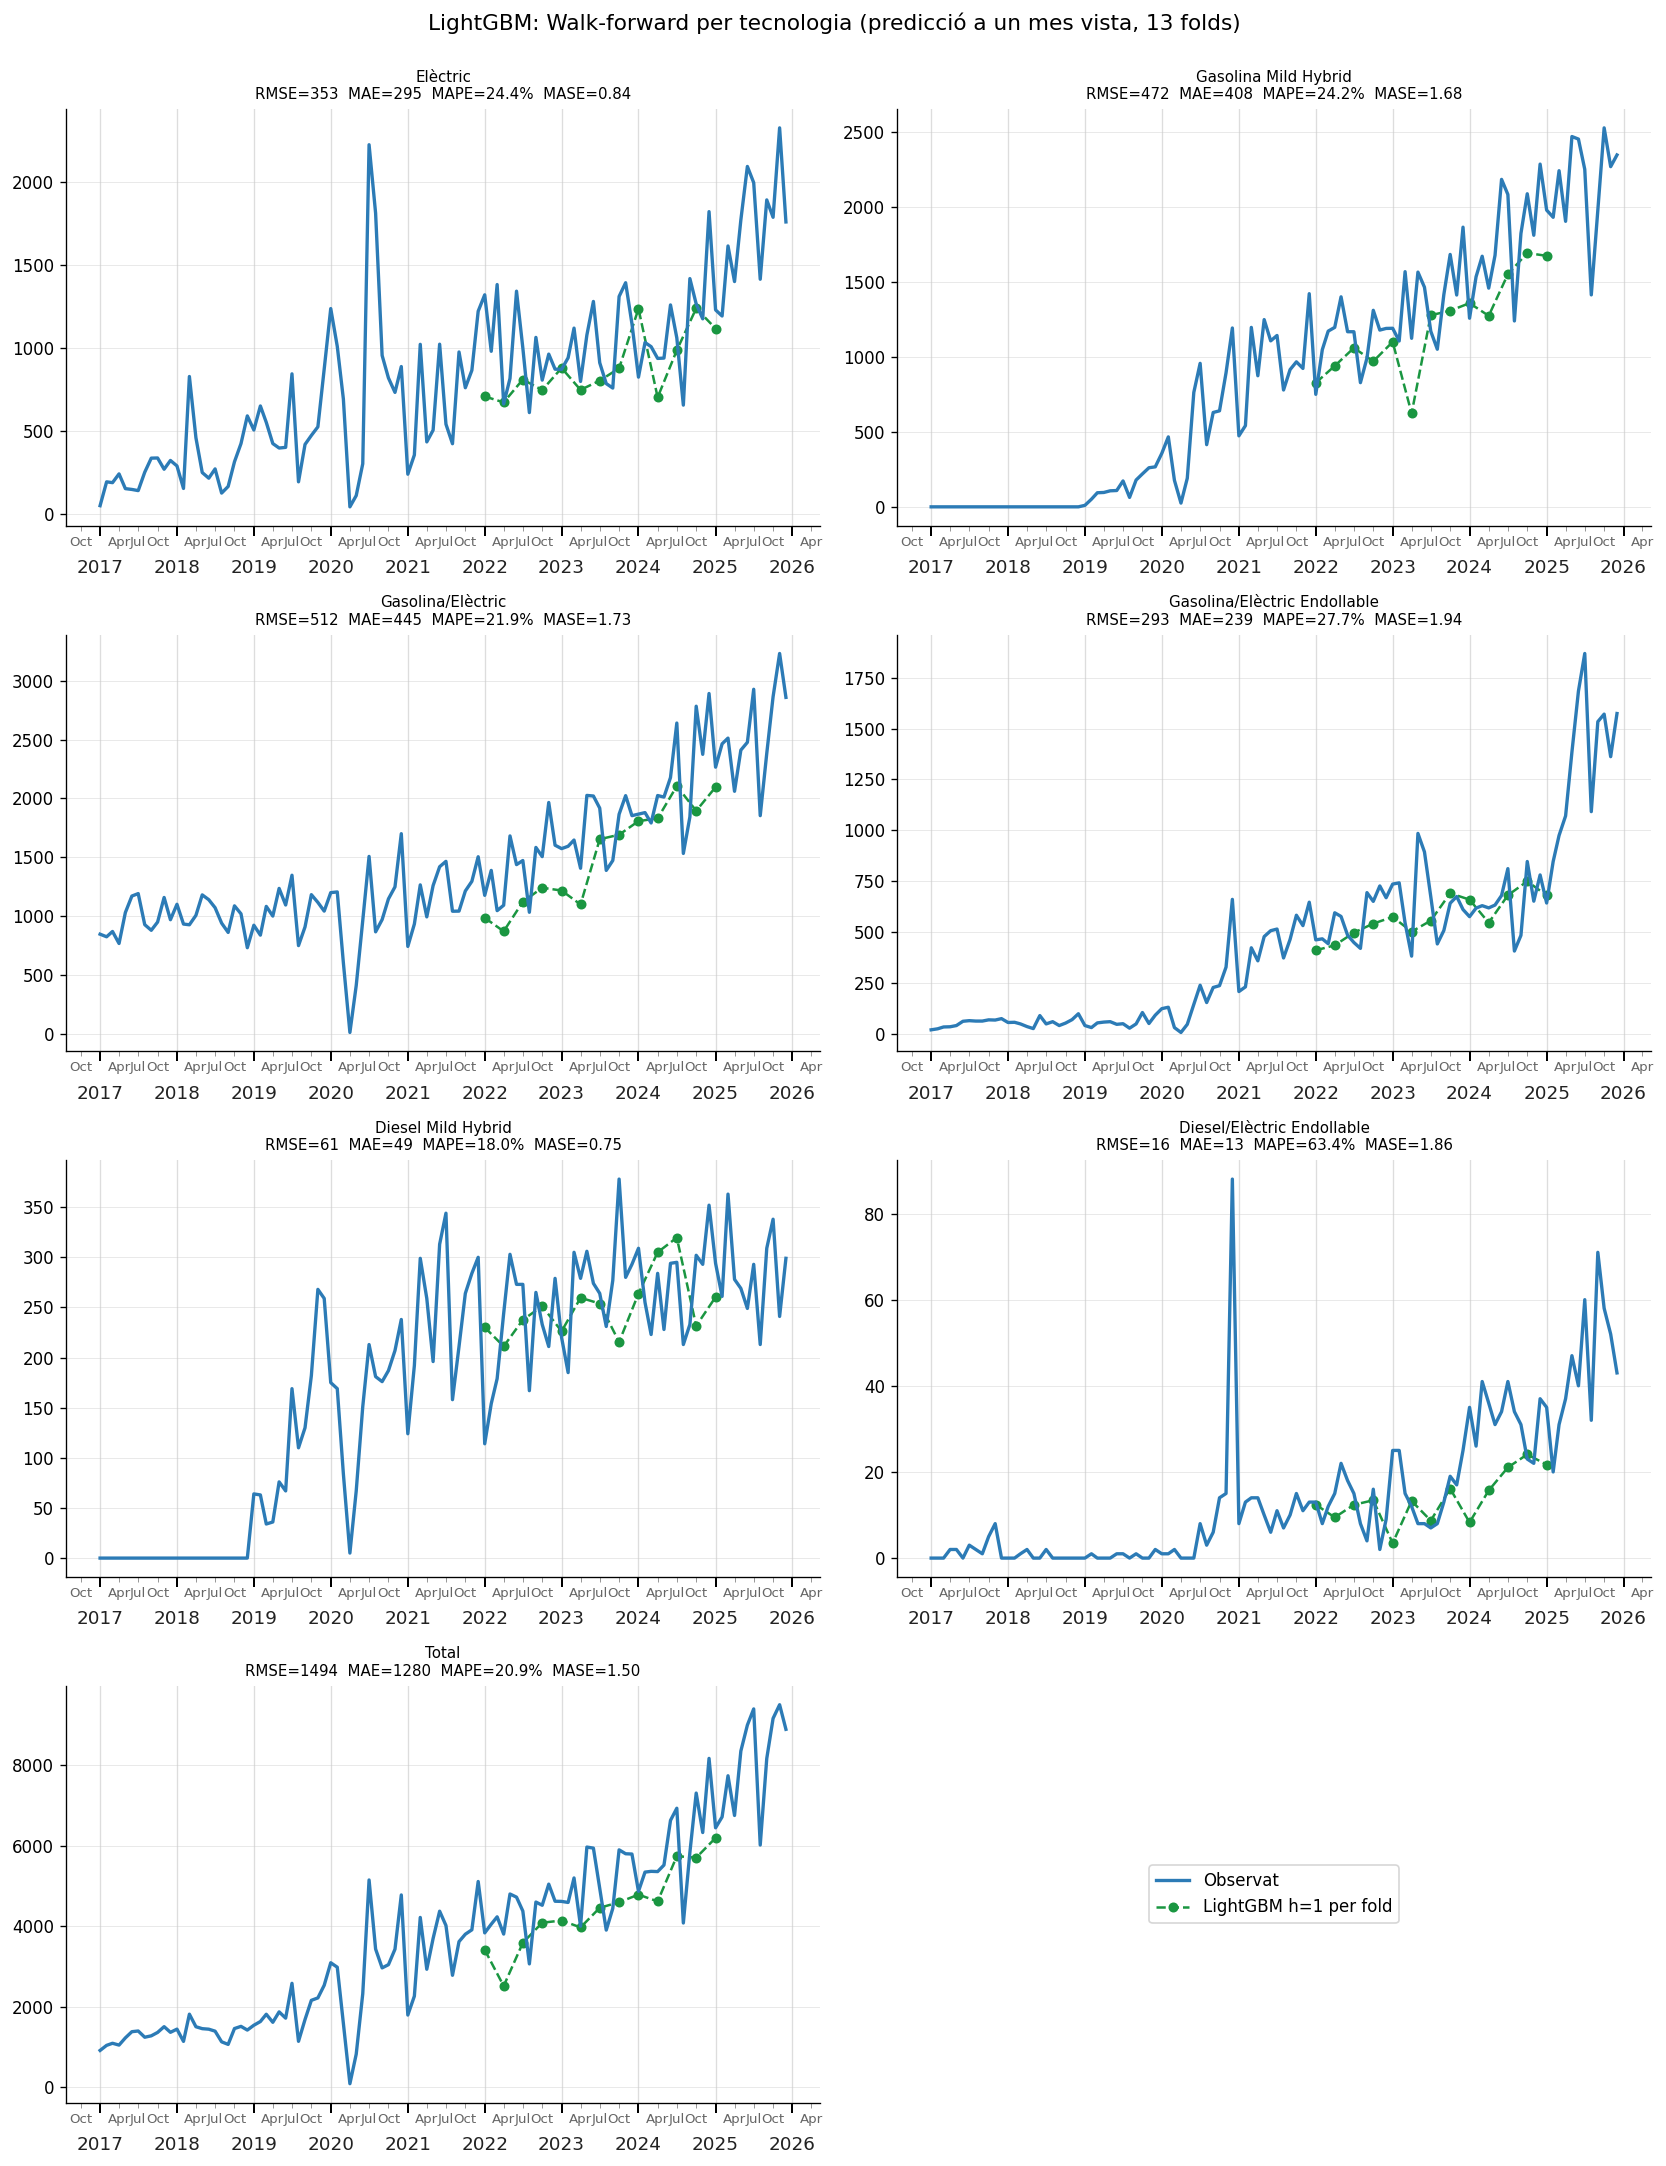

In [9]:
from plotting import plot_wfv_per_tech

plot_wfv_per_tech(
    pivot_full, df_wfv_forecasts, wfv_agg,
    tecnologies=TECNOLOGIES, model_name='LightGBM',
    save_path=FIGURES_DIR / 'fig_lgbm_wfv_per_tech.png',
    color_pred='#1a9641',
)
plt.show()

## 6. Mètriques i guardar resultats


In [10]:
print('Mètriques LightGBM: sèrie Total (backtest):')
print(df_metrics[df_metrics['Tecnologia'] == 'Total'][['RMSE', 'MAE', 'MAPE', 'MASE']].round(2).to_string(index=False))

df_forecasts.to_csv(RESULTS_DIR / 'lgbm_forecasts.csv', index=False)
df_metrics.to_csv(RESULTS_DIR / 'lgbm_metrics.csv', index=False)
df_wfv_metrics.to_csv(RESULTS_DIR / 'lgbm_wfv_metrics.csv', index=False)
df_wfv_forecasts.to_csv(RESULTS_DIR / 'lgbm_wfv_forecasts.csv', index=False)
print('\nGuardats:')
print('  lgbm_forecasts.csv, lgbm_metrics.csv')
print('  lgbm_wfv_metrics.csv, lgbm_wfv_forecasts.csv')

Mètriques LightGBM: sèrie Total (backtest):
   RMSE     MAE  MAPE  MASE
2350.12 2056.62 24.12  2.37

Guardats:
  lgbm_forecasts.csv, lgbm_metrics.csv
  lgbm_wfv_metrics.csv, lgbm_wfv_forecasts.csv
